# 02 · Componente supervisado
**Objetivo:** predecir si un cliente suscribirá el depósito a plazo (`y`).

## 1. Selección y justificación de algoritmos
| Modelo | Por qué es apropiado | Supuestos | Ventajas | Limitaciones |
|---|---|---|---|---|
| Regresión logística | Línea base interpretable | Relación lineal en el log-odds | Coeficientes interpretables, rápida | No captura interacciones |
| Random Forest | Maneja no linealidades y variables mixtas | Ninguno fuerte | Robusto, importancia de variables | Más lento, menos interpretable |
| Gradient Boosting (HistGB) | Suele ser el mejor en datos tabulares | Ninguno fuerte | Alta capacidad predictiva | Riesgo de sobreajuste, más hiperparámetros |

Los tres modelos usan `class_weight="balanced"` porque solo el 11,7 % de los clientes acepta. Escogimos uno lineal y dos de árboles para ver si la relación entre las variables y la aceptación es simple o si necesita algo más flexible. Por ejemplo, en el EDA la edad tenía forma de U y el mes cambiaba mucho la tasa, y eso un modelo lineal no lo capta bien. La justificación completa está en `docs/02_modelos_supervisados.md`.

In [1]:
import sys
sys.path.append("..")   # permite `from src import ...` al ejecutar desde notebooks/

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data_loader import get_train_test, load_data

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test = get_train_test()
print("Train:", X_train.shape, "| Test:", X_test.shape)

from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src import supervised as sup

Train: (36168, 15) | Test: (9043, 15)


## 2. Validación cruzada (solo con entrenamiento)

In [2]:
models = sup.get_models()
cv_results = sup.cross_validate_models(models, X_train, y_train, cv=5)
display(cv_results.round(3))
cv_results.to_csv(config.RESULTS_DIR / "supervisado_cv.csv")

,precision,recall,f1,roc_auc,pr_auc
Regresión logística,0.233,0.660,0.344,0.749,0.372
Random Forest,0.438,0.514,0.473,0.792,0.442
Gradient Boosting,0.357,0.621,0.453,0.798,0.449


## 3. Entrenamiento final y evaluación en prueba

In [3]:
fitted, rows, cms = {}, {}, {}
for name, model in models.items():
    pipe = sup.make_pipeline(model).fit(X_train, y_train)
    fitted[name] = pipe
    rows[name], cms[name] = sup.evaluate(pipe, X_test, y_test)          # umbral 0.5
test_results = pd.DataFrame(rows).T
display(test_results.round(3))
test_results.to_csv(config.RESULTS_DIR / "supervisado_test.csv")

,precision,recall,f1,roc_auc,pr_auc
Regresión logística,0.235,0.678,0.349,0.756,0.373
Random Forest,0.446,0.529,0.484,0.805,0.457
Gradient Boosting,0.363,0.640,0.463,0.805,0.463


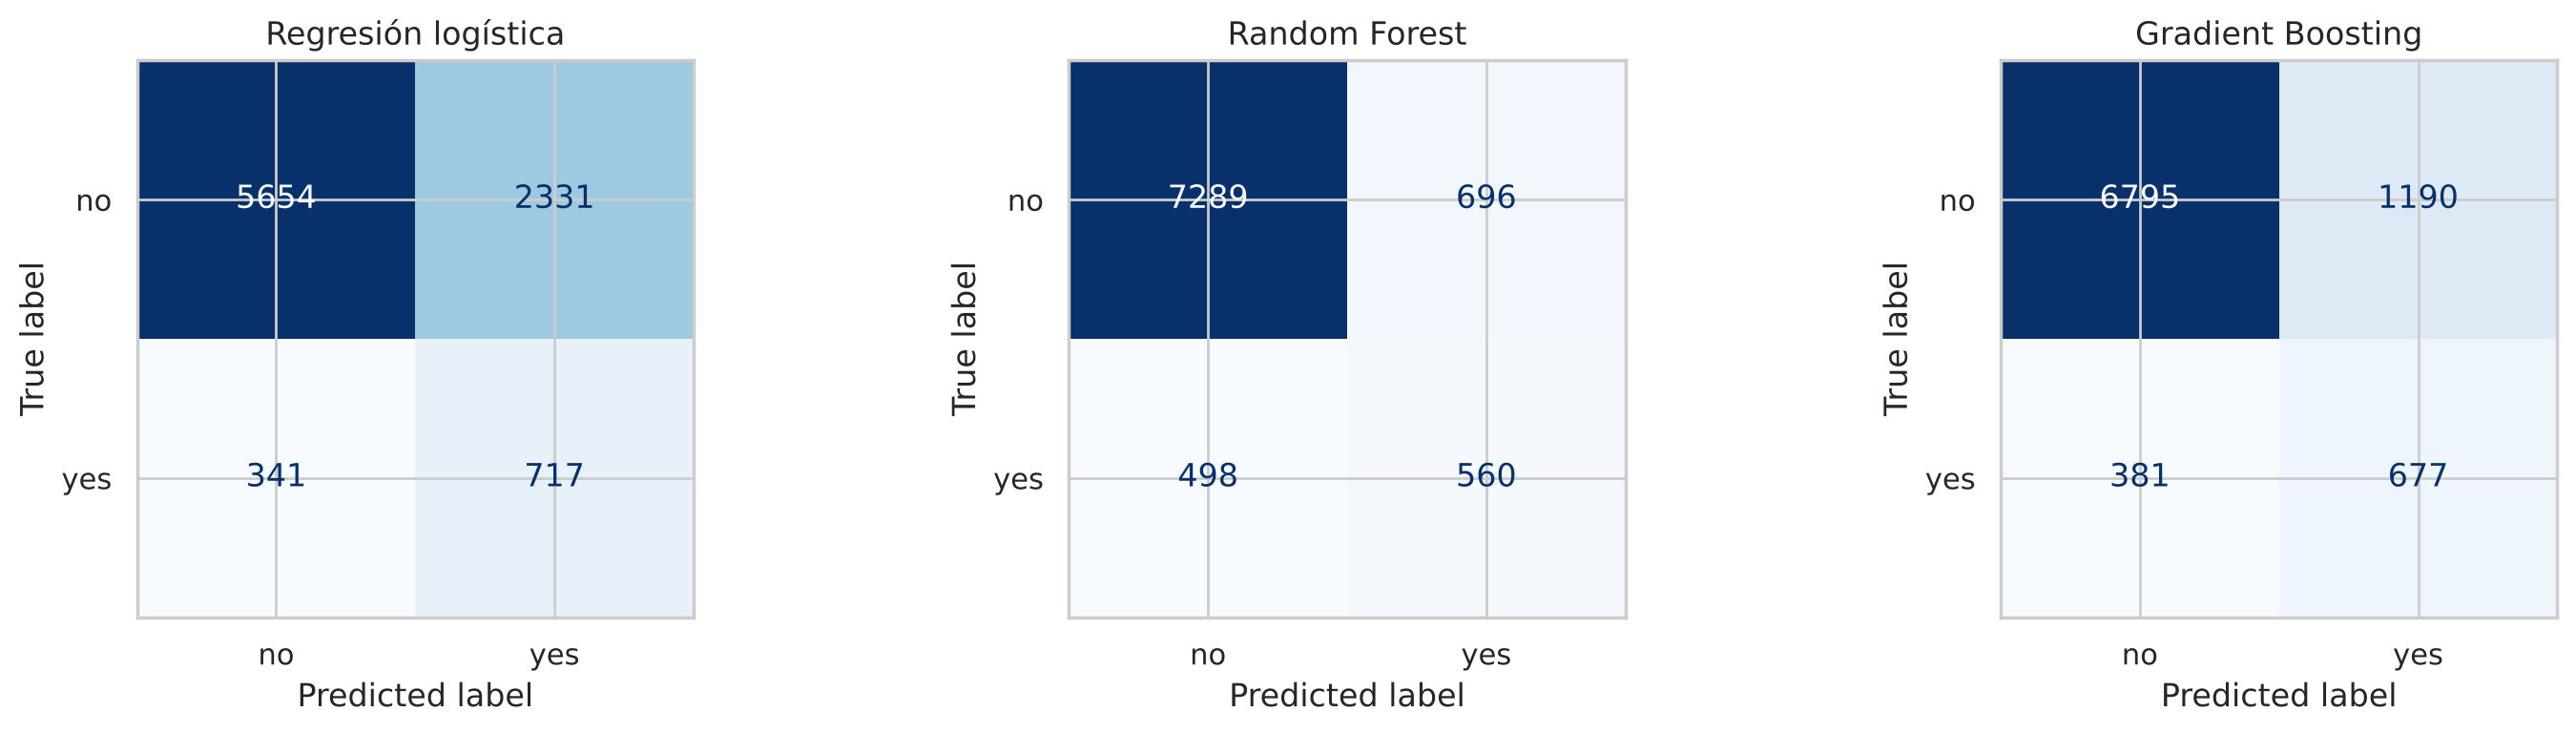

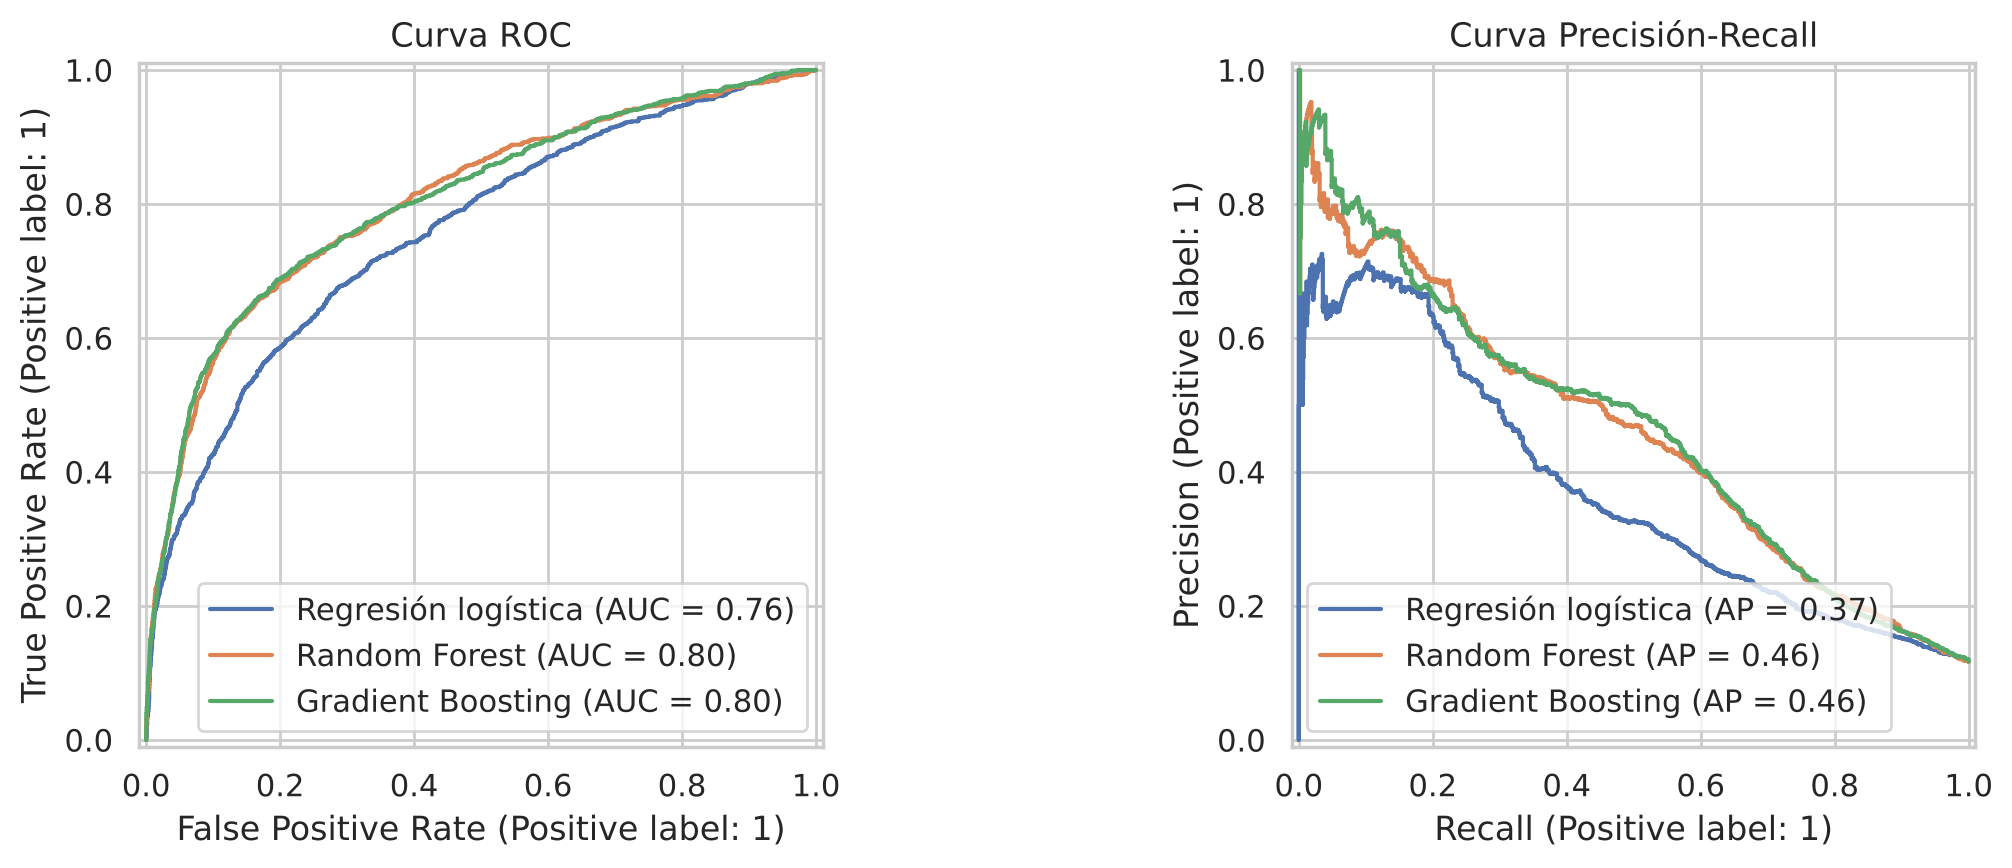

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "sup_matrices_confusion.png", dpi=150); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=a1, name=name)
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, ax=a2, name=name)
a1.set_title("Curva ROC"); a2.set_title("Curva Precisión-Recall")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "sup_curvas.png", dpi=150); plt.show()

**Interpretación:** en validación cruzada y en prueba los dos modelos de árboles le ganan a la regresión logística. En PR-AUC, que es la métrica que más miramos porque hay pocos "yes", Gradient Boosting saca 0,463 en prueba y Random Forest 0,457, mientras que la logística se queda en 0,373. La logística tiene el recall más alto (0,678), pero es porque llama a casi todo el mundo: tiene 2.331 falsos positivos, o sea que de cada 100 personas que dice que van a aceptar solo 23 aceptan de verdad.

Para el banco los dos errores no cuestan lo mismo. Un falso positivo es una llamada perdida, que cuesta poco. Un falso negativo es un cliente que sí iba a comprar y no se llamó, y eso es plata que se pierde. Por eso no nos sirve un modelo con buena precisión pero recall bajo. Random Forest tiene la mejor precisión (0,446), pero deja sin llamar a 498 clientes interesados; Gradient Boosting deja 381 y logra un mejor equilibrio.

No vemos sobreajuste: las métricas de prueba son casi iguales a las de la validación cruzada (en PR-AUC, 0,449 contra 0,463 en Gradient Boosting y 0,442 contra 0,457 en Random Forest). Incluso salen un poquito mejores en prueba, que lo tomamos como variación normal del split.

## 4. Selección de variables y reducción de dimensionalidad
Comparamos, con validación cruzada sobre entrenamiento, cuatro estrategias aplicadas **después** del
preprocesamiento y **dentro** del pipeline (se ajustan solo con cada fold de entrenamiento):
sin selección, información mutua (k = 20), L1 (regresión logística con penalización L1) y PCA (95 % de varianza).

In [5]:
sel_models = {k: models[k] for k in ["Regresión logística", "Gradient Boosting"]}   # un modelo lineal y uno de árboles
sel_results = sup.compare_selectors(sel_models, sup.get_selectors(), X_train, y_train, cv=5)
display(sel_results.round(3))
sel_results.to_csv(config.RESULTS_DIR / "supervisado_seleccion_variables.csv")

precision  recall     f1  \
modelo              selección                                            
Regresión logística Sin selección                 0.233   0.660  0.344   
                    Información mutua (k=20)      0.224   0.667  0.336   
                    L1 (SelectFromModel)          0.233   0.663  0.345   
                    PCA (95 % varianza)           0.210   0.685  0.321   
Gradient Boosting   Sin selección                 0.357   0.621  0.453   
                    Información mutua (k=20)      0.346   0.614  0.443   
                    L1 (SelectFromModel)          0.358   0.625  0.455   
                    PCA (95 % varianza)           0.305   0.604  0.405   

                                              roc_auc  pr_auc  
modelo              selección                                  
Regresión logística Sin selección               0.749   0.372  
                    Información mutua (k=20)    0.743   0.358  
                    L1 (SelectFromModel)        0.750   0.372  
                    PCA (95 % varianza)         0.732   0.296  
Gradient Boosting   Sin selección               0.798   0.449  
                    Información mutua (k=20)    0.792   0.434  
                    L1 (SelectFromModel)        0.800   0.444  
                    PCA (95 % varianza)         0.767   0.372

In [6]:
# ¿Cuántas variables conserva cada selector? (ajustado con todo el entrenamiento)
for s_name, selector in sup.get_selectors().items():
    if selector is None:
        continue
    p = sup.make_pipeline(models["Regresión logística"], selector).fit(X_train, y_train)
    n_out = p.named_steps["select"].transform(p.named_steps["prep"].transform(X_train[:5])).shape[1]
    print(f"{s_name}: {n_out} variables/componentes")

Información mutua (k=20): 20 variables/componentes


L1 (SelectFromModel): 29 variables/componentes
PCA (95 % varianza): 19 variables/componentes


**Interpretación:** la selección de variables no mejoró nada. Con Gradient Boosting el PR-AUC pasó de 0,449 sin selección a 0,434 con información mutua (k = 20) y a 0,444 con L1, y con la regresión logística L1 quedó igual (0,372) e información mutua bajó a 0,358. PCA fue lo peor en los dos modelos (0,372 en Gradient Boosting y 0,296 en la logística).

Esto tiene sentido con el EDA. Allí vimos que ninguna variable sola explica mucho (la información mutua más alta era apenas 0,028) y que las que salían "casi irrelevantes" eran dummies sueltas de `job` o `marital`. Al quitarlas el modelo pierde un poco, porque juntas sí aportan algo. PCA además mezcla todas las variables en componentes y el modelo deja de ver cosas como el mes o el resultado de la campaña anterior por separado. La reducción le afecta más a la logística, que depende más de que las variables estén "limpias".

**Decisión final:** no usamos selección. Con 41 columnas los modelos entrenan rápido, así que no ganamos nada reduciendo y sí perdemos un poco de rendimiento e interpretabilidad (sobre todo con PCA).

## 5. Optimización de hiperparámetros
`RandomizedSearchCV` (15 combinaciones, validación cruzada de 3 folds) optimizando **PR-AUC**, la métrica más
informativa con clases desbalanceadas. La búsqueda usa solo el conjunto de entrenamiento. _(Puede tardar varios minutos.)_

In [7]:
tuned, tune_rows, times = {}, {}, {}
for name, model in models.items():
    search, secs = sup.tune_model(name, model, X_train, y_train, n_iter=15, cv=3)
    tuned[name], times[name] = search, secs
    tune_rows[name] = {"mejor_pr_auc_cv": search.best_score_, "segundos": secs, **search.best_params_}
    print(f"{name}: PR-AUC CV = {search.best_score_:.3f} ({secs:.0f} s)")
display(pd.DataFrame(tune_rows).T)
pd.DataFrame(tune_rows).T.to_csv(config.RESULTS_DIR / "supervisado_hiperparametros.csv")

Regresión logística: PR-AUC CV = 0.372 (5 s)


Random Forest: PR-AUC CV = 0.443 (178 s)


Gradient Boosting: PR-AUC CV = 0.450 (22 s)


,mejor_pr_auc_cv,segundos,model__C,model__min_samples_leaf,model__max_features,model__max_depth,model__l2_regularization,model__learning_rate,model__max_leaf_nodes
Regresión logística,0.371798,5.467012,0.074593,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,0.443311,178.103683,NaN,5.0,0.3,NaN,NaN,NaN,NaN
Gradient Boosting,0.449546,22.111582,NaN,100.0,NaN,NaN,0.540822,0.104338,63.0


In [8]:
# Línea base vs optimizado, en prueba
rows_tuned = {}
for name, search in tuned.items():
    rows_tuned[name], _ = sup.evaluate(search.best_estimator_, X_test, y_test)
tuned_results = pd.DataFrame(rows_tuned).T
comparison = pd.concat({"base": test_results, "optimizado": tuned_results}, axis=1)
display(comparison.round(3))
comparison.to_csv(config.RESULTS_DIR / "supervisado_base_vs_optimizado.csv")

base                              optimizado         \
                    precision recall     f1 roc_auc pr_auc  precision recall   
Regresión logística     0.235  0.678  0.349   0.756  0.373      0.235  0.680   
Random Forest           0.446  0.529  0.484   0.805  0.457      0.486  0.493   
Gradient Boosting       0.363  0.640  0.463   0.805  0.463      0.353  0.646   

                                           
                        f1 roc_auc pr_auc  
Regresión logística  0.349   0.756  0.373  
Random Forest        0.490   0.806  0.461  
Gradient Boosting    0.457   0.806  0.467

**Interpretación:** la optimización mejoró muy poco. En validación cruzada Gradient Boosting pasó de 0,449 a 0,450 de PR-AUC, Random Forest se quedó prácticamente igual (0,442 a 0,443) y la logística no cambió (0,372). En prueba el mejor resultado fue Gradient Boosting con PR-AUC 0,467, frente a 0,463 sin optimizar. Los mejores parámetros fueron `learning_rate` ≈ 0,10, `max_leaf_nodes` = 63, `min_samples_leaf` = 100 y `l2_regularization` ≈ 0,54 para Gradient Boosting, y `min_samples_leaf` = 5 y `max_features` = 0,3 para Random Forest.

Que la mejora sea tan pequeña nos dice que el problema no está en los parámetros sino en la información que tenemos. Sin `duration` el modelo solo sabe quién es el cliente y cómo ha sido la campaña, no cómo le fue en la llamada, y con eso hay un techo cerca de 0,46-0,47 de PR-AUC. Aun así ese valor es casi cuatro veces el 0,117 que daría adivinar al azar.

## 6. Comparación y selección del modelo
**Criterios (definidos antes de mirar los resultados):**
1. **PR-AUC y F1 en prueba** (principales, por el desbalance).
2. **Recall**: el banco prefiere no perder clientes interesados, siempre que la Precision no se desplome.
3. **Estabilidad**: diferencia entre PR-AUC de CV y de prueba (sobreajuste).
4. **Interpretabilidad** y **costo computacional** (tiempo de búsqueda/entrenamiento).

In [9]:
ranking = pd.DataFrame({
    "pr_auc": tuned_results["pr_auc"], "f1": tuned_results["f1"], "recall": tuned_results["recall"],
    "roc_auc": tuned_results["roc_auc"],
    "brecha_cv_vs_test": [tuned[n].best_score_ - tuned_results.loc[n, "pr_auc"] for n in tuned_results.index],
    "segundos_busqueda": pd.Series(times),
})
ranking["rank_medio"] = ranking[["pr_auc", "f1"]].rank(ascending=False).mean(axis=1)
ranking = ranking.sort_values(["rank_medio", "pr_auc"], ascending=[True, False])   # empate -> mayor PR-AUC
display(ranking.round(3))
ranking.to_csv(config.RESULTS_DIR / "supervisado_ranking_modelos.csv")

best_name = ranking.index[0]          # ajustar manualmente si el equipo argumenta otro criterio
final_pipe = tuned[best_name].best_estimator_
print("Modelo seleccionado:", best_name)

,pr_auc,f1,recall,roc_auc,brecha_cv_vs_test,segundos_busqueda,rank_medio
Gradient Boosting,0.467,0.457,0.646,0.806,-0.018,22.112,1.5
Random Forest,0.461,0.490,0.493,0.806,-0.018,178.104,1.5
Regresión logística,0.373,0.349,0.680,0.756,-0.001,5.467,3.0


Modelo seleccionado: Gradient Boosting


**Selección argumentada:** escogimos **Gradient Boosting**.

- **PR-AUC:** es el más alto en prueba (0,467, frente a 0,461 de Random Forest y 0,373 de la logística).
- **F1:** aquí gana Random Forest (0,490 contra 0,457), por eso quedaron empatados en el ranking. Desempatamos con PR-AUC porque no depende del umbral, y el umbral lo vamos a ajustar después.
- **Recall:** Gradient Boosting encuentra el 64,6 % de los que aceptan y Random Forest solo el 49,3 %. Para el banco es más importante no dejar pasar clientes interesados.
- **Estabilidad:** los dos tienen la misma brecha entre CV y prueba (−0,018), así que ninguno sobreajusta.
- **Costo computacional:** la búsqueda de Gradient Boosting tardó 23 segundos y la de Random Forest 179, casi ocho veces más.

Lo que sacrificamos es interpretabilidad: con la regresión logística podríamos leer los coeficientes directamente, pero rinde bastante menos. Por eso usamos la importancia por permutación para explicar el modelo.

Hay que decir que la diferencia en PR-AUC entre Gradient Boosting y Random Forest es muy pequeña (0,006) y probablemente está dentro del ruido de la validación cruzada. Lo que sí es claro es que los dos de árboles son mejores que la logística. Nos quedamos con Gradient Boosting por el recall y porque es más rápido.

## 7. Ajuste del umbral de decisión
Con clases desbalanceadas el umbral 0.5 rara vez es el mejor. Lo elegimos con **predicciones de
validación cruzada sobre entrenamiento** (nunca con prueba) y luego lo aplicamos a prueba.

Umbral óptimo (F1, validación): 0.616


,umbral 0.5,umbral 0.62
precision,0.353,0.442
recall,0.646,0.557
f1,0.457,0.493
roc_auc,0.806,0.806
pr_auc,0.467,0.467


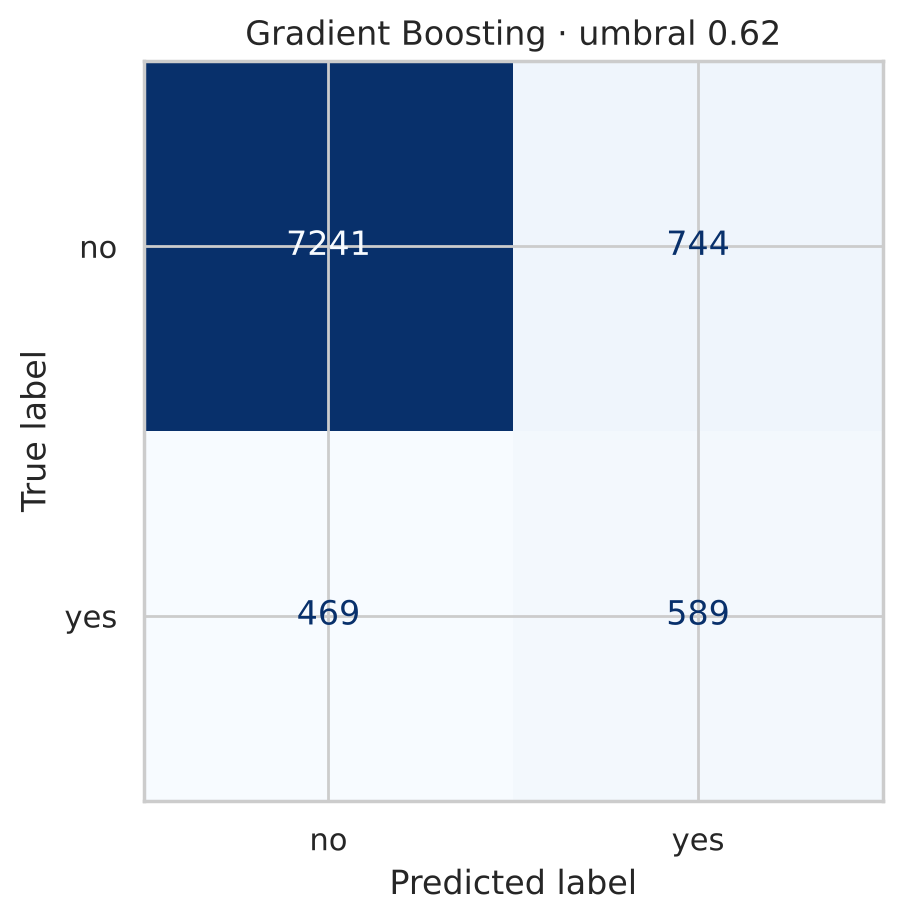

In [10]:
from sklearn.base import clone
skf = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
oof = cross_val_predict(clone(final_pipe), X_train, y_train, cv=skf, method="predict_proba")[:, 1]
thr = sup.best_f1_threshold(y_train, oof)
print(f"Umbral óptimo (F1, validación): {thr:.3f}")
metrics_thr, cm_thr = sup.evaluate(final_pipe, X_test, y_test, threshold=thr)
display(pd.DataFrame({"umbral 0.5": tuned_results.loc[best_name], f"umbral {thr:.2f}": pd.Series(metrics_thr)}).round(3))
ConfusionMatrixDisplay(cm_thr, display_labels=["no", "yes"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{best_name} · umbral {thr:.2f}")
plt.savefig(config.FIGURES_DIR / "sup_matriz_umbral_optimo.png", dpi=150, bbox_inches="tight"); plt.show()

In [11]:
# Ganancia supuesta: cada llamada cuesta 1 y cada suscripción vale 10
def ganancia(y, prob, umbral, costo=1, valor=10):
    llamar = prob >= umbral
    return valor * (llamar & (y == 1)).sum() - costo * llamar.sum()

y_tr, y_te = np.asarray(y_train), np.asarray(y_test)
umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
thr_costo = umbrales[np.argmax([ganancia(y_tr, oof, u) for u in umbrales])]   # elegido con validación, no con prueba
print(f"Umbral que maximiza la ganancia en validación: {thr_costo:.2f}")

p_test = final_pipe.predict_proba(X_test)[:, 1]
filas = []
for nombre, u in [("llamar a todos", 0.0), ("umbral 0.5", 0.5), (f"umbral costo {thr_costo:.2f}", thr_costo), (f"umbral F1 {thr:.2f}", thr)]:
    llamar = p_test >= u
    filas.append({"criterio": nombre, "llamadas": int(llamar.sum()), "suscripciones": int((llamar & (y_te == 1)).sum()),
                  "recall": (llamar & (y_te == 1)).sum() / (y_te == 1).sum(), "ganancia": int(ganancia(y_te, p_test, u))})
costos = pd.DataFrame(filas).set_index("criterio")
display(costos.round(3))
costos.to_csv(config.RESULTS_DIR / "supervisado_costos_umbral.csv")

Umbral que maximiza la ganancia en validación: 0.47


,llamadas,suscripciones,recall,ganancia
criterio,,,,
llamar a todos,9043,1058,1.000,1537
umbral 0.5,1933,683,0.646,4897
umbral costo 0.47,2170,704,0.665,4870
umbral F1 0.62,1333,589,0.557,4557


**Interpretación:** al subir el umbral de 0,5 a 0,62 el modelo se vuelve más exigente para decir "yes". La precisión sube de 0,353 a 0,442 y el F1 de 0,457 a 0,493, pero el recall baja de 0,646 a 0,557. En la matriz de confusión eso se ve así: pasamos de 1.933 a 1.333 llamadas, pero se nos escapan 94 clientes que sí iban a aceptar (de 683 a 589 encontrados). El ROC-AUC y el PR-AUC no cambian porque no dependen del umbral.

En la celda de arriba hicimos la cuenta con costos supuestos (cada llamada cuesta 1 y cada suscripción vale 10). Con eso el umbral de 0,62 deja **menos** ganancia que el de 0,5, porque cada cliente perdido cuesta mucho más que una llamada de más. Buscando el umbral que maximiza la ganancia en la validación cruzada nos sale uno más bajo, alrededor de 0,47, que en prueba da una ganancia parecida a la de 0,5 y muy por encima de llamar a todo el mundo.

Entonces el umbral "óptimo" depende de lo que el banco quiera: si le preocupa no saturar a los clientes con llamadas, conviene 0,62; si lo que importa es vender, con estos costos conviene quedarse en 0,5 o un poco menos. Lo que no conviene es llamar a todos.

## 8. Importancia de variables (influencia de lo demográfico, financiero y de campaña)

,variable,importancia
0,month,0.0868
1,contact,0.0633
2,poutcome,0.0286
3,day,0.0265
4,balance,0.0107
5,age,0.0102
6,housing,0.0100
7,campaign,0.0083
8,marital,0.0071
9,pdays,0.0039


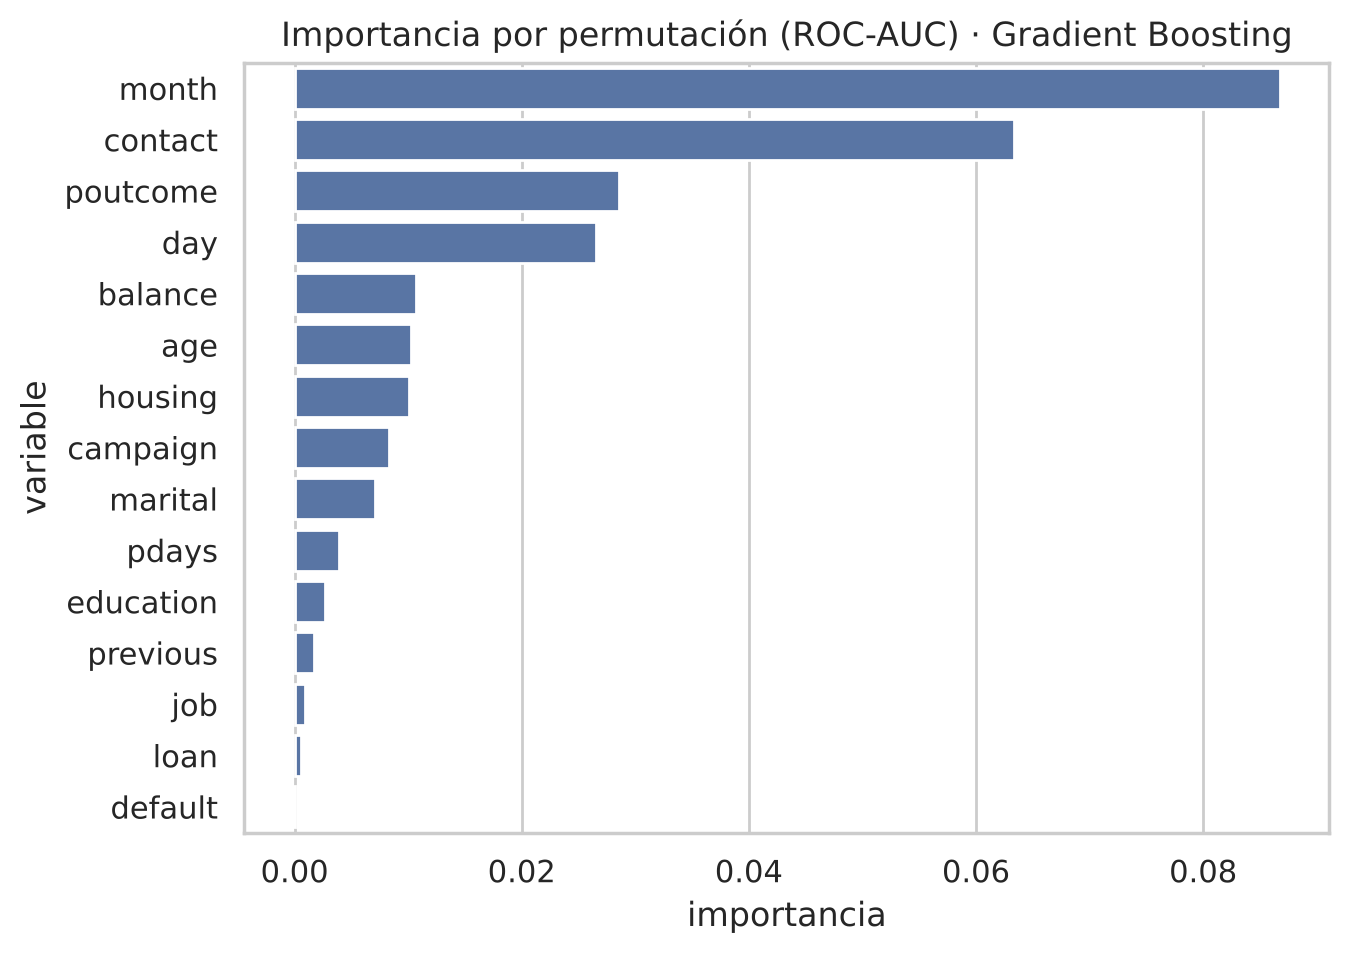

In [12]:
imp = sup.permutation_importances(final_pipe, X_test, y_test)
display(imp.round(4))
plt.figure(figsize=(7, 5))
sns.barplot(data=imp, y="variable", x="importancia", color="#4C72B0")
plt.title(f"Importancia por permutación (ROC-AUC) · {best_name}")
plt.savefig(config.FIGURES_DIR / "sup_importancia.png", dpi=150, bbox_inches="tight"); plt.show()
imp.to_csv(config.RESULTS_DIR / "supervisado_importancia.csv", index=False)

**Interpretación:** las variables que más pesan son las de la campaña y el momento de la llamada, no las del cliente. El mes es la más importante (0,087), seguida del tipo de contacto (0,063), el resultado de la campaña anterior (0,029) y el día (0,027). Después vienen `balance`, la edad y si tiene hipoteca, todas alrededor de 0,010. Variables como el trabajo, el préstamo o la mora casi no cambian nada.

Esto coincide con el EDA. Allí vimos que mayo tenía muchas llamadas y muy poca aceptación, que `poutcome = success` aceptaba un 64,6 % y que `contact = unknown` casi no aceptaba. Lo demográfico (edad, estado civil, educación) aparece, pero con menos peso.

Hay que tener cuidado con dos cosas. Primero, `contact` y el mes están relacionados (el `unknown` se concentraba en mayo y junio), y cuando dos variables se parecen la permutación puede repartir la importancia entre ellas o subestimar alguna, porque el modelo usa la otra como reemplazo. Lo mismo pasa con `pdays` y `previous`, que por eso salen bajas aunque en el EDA importaban. Segundo, la importancia dice cuánto depende el modelo de una variable, no que esa variable *cause* que el cliente acepte.

## 9. Conclusiones del componente supervisado
- **¿El modelo identifica a los clientes que aceptan?** En parte. Con Gradient Boosting y umbral 0,5 encontramos el 64,6 % de los que aceptan (683 de 1.058), y de cada 100 que llamamos aceptan unos 35, frente a 12 si se llamara al azar. El ROC-AUC es 0,806 y el PR-AUC 0,467. No es un modelo perfecto, pero sí ayuda bastante a priorizar a quién llamar.
- **Limitaciones de las métricas:** el ROC-AUC de 0,806 se ve bien, pero con tan pocos "yes" es optimista; el PR-AUC de 0,467 muestra mejor que todavía hay muchos falsos positivos. Precision, recall y F1 cambian mucho según el umbral, y el análisis de ganancia depende de costos que nosotros supusimos. Además todo se evaluó en un solo split de prueba, entonces las diferencias pequeñas entre modelos pueden ser suerte.
- **Dificultades:** el desbalance (por eso usamos pesos de clase y PR-AUC), quitar `duration`, que era la variable más fuerte pero solo se conoce después de la llamada, y decidir el umbral, porque el mejor según F1 no es el mejor para el negocio.
- **Recomendación:** usar el modelo para ordenar la lista de clientes por probabilidad y llamar primero a los de arriba, con un umbral cerca de 0,5 si el objetivo es vender. Antes de usarlo de verdad habría que validar los costos reales con el banco, probarlo en una campaña nueva y reentrenarlo cada cierto tiempo, porque depende mucho del mes y del canal.